# 01 — Exploratory Data Analysis & Data Cleaning
**ShopSense: E-Commerce Customer Value & Purchase Prediction**
DEPI Graduation Project — IBM Data Scientist Track (CAI5_AIS4_S4)

**Phase 1 scope:** load the raw competition data, audit its quality, clean it, and explore the patterns that will drive cleaning decisions, feature engineering and modeling in the next phases.

**Data source:** Kaggle competition *Global E-Commerce Customer Purchase Prediction* (8 files, loaded from `../data/`).

**Contents**
1. Setup & raw data loading
2. Data quality audit
3. Data cleaning
4. Exploratory analysis (customers, transactions, sessions, context tables)
5. Target variable analysis
6. Key findings & implications for Phase 2

## 1. Setup & raw data loading

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (10, 5)

DATA = "../data/"
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.3.3 | numpy 2.2.6


In [2]:
customers   = pd.read_csv(DATA + "customers.csv")
geo_data    = pd.read_csv(DATA + "geo_data.csv")
campaigns   = pd.read_csv(DATA + "marketing_campaigns.csv")
sub_sample  = pd.read_csv(DATA + "sample_submission.csv")
sessions    = pd.read_csv(DATA + "sessions.csv")
transactions= pd.read_csv(DATA + "transactions.csv")
train       = pd.read_csv(DATA + "train.csv")
test        = pd.read_csv(DATA + "test.csv")

tables = {"customers": customers, "transactions": transactions, "sessions": sessions,
          "train": train, "test": test, "sample_submission": sub_sample,
          "geo_data": geo_data, "marketing_campaigns": campaigns}

overview = pd.DataFrame({
    name: {"rows": len(df), "columns": df.shape[1],
           "memory_mb": round(df.memory_usage(deep=True).sum() / 1e6, 1)}
    for name, df in tables.items()}).T
overview

,rows,columns,memory_mb
customers,"200,000.000",17.000,105.000
transactions,"500,000.000",11.000,209.700
sessions,"2,000,000.000",11.000,732.300
train,"160,000.000",2.000,2.600
test,"40,000.000",1.000,0.300
sample_submission,"40,000.000",2.000,0.600
geo_data,100.000,5.000,0.000
marketing_campaigns,200.000,6.000,0.100


**Reading of the landscape**

* `customers` — one row per customer (200k). Profile attributes plus 5 `noise_customer_*` columns.
* `transactions` — 500k orders. Note: `order_value` is stored as **text** (`"$83.08"`), and the flag columns mix boolean encodings.
* `sessions` — 2M web sessions, linkable to `customers`, `marketing_campaigns` and `geo_data`.
* `train` / `test` — the competition split: 160k labeled customers, 40k to score. Disjoint, together covering all 200k customers.

In [3]:
customers.head(3)

,customer_id,age,country_code,region,signup_date,loyalty_score,email_open_rate,discount_usage_rate,avg_review_score,referral_code,customer_tier,credit_limit,noise_customer_0,noise_customer_1,noise_customer_2,noise_customer_3,noise_customer_4
0,0,73,usa,region_50,2022-08-02,0.244,0.660,0.238,4.838,REF_904704,Bronze,"$10,966",-0.349,0.745,0.044,-1.713,2.180
1,1,47,U.S.,region_3,2023-06-14,0.196,0.258,0.332,4.448,REF_183413,Silver,"$14,189",-0.330,-0.416,-0.514,0.584,0.833
2,2,67,USA,region_54,2024-01-06,0.326,0.158,0.003,3.641,REF_535074,Platinum,"$15,043",-0.609,-0.669,0.637,0.629,0.257


In [4]:
transactions.head(3)

,transaction_id,customer_id,transaction_timestamp,order_value,items_count,payment_method,discount_applied,shipping_speed,high_value_flag,noise_trans_0,noise_trans_1
0,0,106636,2023-11-21,$20.39,1,debit_card,1,overnight,No,0.100,0.123
1,1,6512,2024-05-08,$181.53,1,paypal,TRUE,overnight,No,0.285,-0.836
2,2,172988,2024-09-12,$107.92,7,paypal,FALSE,express,No,0.385,-0.434


In [5]:
sessions.head(3)

,session_id,customer_id,session_timestamp,session_duration,pages_viewed,cart_additions,bounce_flag,traffic_source,device_type,campaign_id,geo_ip_region
0,0,98947,2022-01-26,699.425,2.000,4,0,organic,Desktop,105,region_74
1,1,180169,2023-05-19,127.087,8.000,2,FALSE,organic,mobile,155,region_15
2,2,196195,2022-03-24,99.649,3.000,3,1,Organic,Desktop,183,region_37


In [6]:
train["target"].value_counts().rename_axis("target").to_frame("customers").assign(
    share=lambda d: (d["customers"] / len(train)).round(4))

,customers,share
target,,
0,127514,0.797
1,32486,0.203


## 2. Data quality audit
Before cleaning, a systematic audit: missing values, duplicates, identifier integrity, and format inconsistencies.

In [7]:
def quality_report(df, name):
    rep = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "missing_%": (df.isna().mean() * 100).round(2),
        "n_unique": df.nunique(),
    })
    print(f"--- {name}: {df.shape[0]:,} rows x {df.shape[1]} cols | duplicated full rows: {df.duplicated().sum():,}")
    return rep

quality_report(customers, "customers")

--- customers: 200,000 rows x 17 cols | duplicated full rows: 0


,dtype,missing,missing_%,n_unique
customer_id,int64,0,0.000,200000
age,object,0,0.000,58
country_code,object,0,0.000,10
region,object,0,0.000,100
signup_date,object,0,0.000,1000
loyalty_score,float64,0,0.000,891
email_open_rate,float64,22746,11.370,177254
discount_usage_rate,float64,0,0.000,200000
avg_review_score,float64,0,0.000,200000
referral_code,object,0,0.000,179259


In [8]:
quality_report(transactions, "transactions")

--- transactions: 500,000 rows x 11 cols | duplicated full rows: 0


,dtype,missing,missing_%,n_unique
transaction_id,int64,0,0.000,500000
customer_id,int64,0,0.000,183541
transaction_timestamp,object,0,0.000,1000
order_value,object,0,0.000,51662
items_count,int64,0,0.000,15
payment_method,object,0,0.000,4
discount_applied,object,0,0.000,6
shipping_speed,object,0,0.000,3
high_value_flag,object,0,0.000,2
noise_trans_0,float64,0,0.000,500000


In [9]:
quality_report(sessions, "sessions")

--- sessions: 2,000,000 rows x 11 cols | duplicated full rows: 0


,dtype,missing,missing_%,n_unique
session_id,int64,0,0.000,2000000
customer_id,int64,0,0.000,199990
session_timestamp,object,0,0.000,1000
session_duration,float64,0,0.000,2000000
pages_viewed,float64,100000,5.000,22
cart_additions,int64,0,0.000,14
bounce_flag,object,0,0.000,6
traffic_source,object,0,0.000,6
device_type,object,0,0.000,5
campaign_id,int64,0,0.000,200


### 2.1 Identifier integrity
Every modeling table must join cleanly to `customers`.

In [10]:
cids = set(customers["customer_id"])
checks = {
    "customer_id unique in customers": customers["customer_id"].is_unique,
    "train ids found in customers": train["customer_id"].isin(cids).mean(),
    "test ids found in customers": test["customer_id"].isin(cids).mean(),
    "train/test overlap": len(set(train.customer_id) & set(test.customer_id)),
    "transaction ids found in customers": transactions["customer_id"].isin(cids).mean(),
    "session ids found in customers": sessions["customer_id"].isin(cids).mean(),
    "transaction_id unique": transactions["transaction_id"].is_unique,
    "session_id unique": sessions["session_id"].is_unique,
    "session geo_ip_region in geo_data": sessions["geo_ip_region"].isin(set(geo_data.geo_ip_region)).mean(),
    "session campaign_id in campaigns": sessions["campaign_id"].isin(set(campaigns.campaign_id)).mean(),
}
pd.Series(checks, name="result").to_frame()

,result
customer_id unique in customers,True
train ids found in customers,1.000
test ids found in customers,1.000
train/test overlap,0
transaction ids found in customers,1.000
session ids found in customers,1.000
transaction_id unique,True
session_id unique,True
session geo_ip_region in geo_data,1.000
session campaign_id in campaigns,1.000


All joins are clean: every ID resolves, train and test are disjoint and together cover exactly the 200,000 customers.

### 2.2 Format inconsistencies found
The raw files contain deliberate dirtiness. Documented before fixing:

| Column | Problem |
|---|---|
| `customers.age` | 10,000 rows are the string `"unknown"` |
| `customers.credit_limit` | currency text: `"$1,627"` |
| `customers.country_code` | same country in many spellings: `usa` / `USA` / `U.S.` / `US`, `uk` / `UK`, `de` / `DE` |
| `transactions.order_value` | currency text: `"$83.08"`, some with thousands separators |
| `transactions.discount_applied` | six encodings of a boolean: `0/1/TRUE/FALSE/Yes/No` |
| `transactions.high_value_flag` | `Yes/No` |
| `sessions.bounce_flag` | same six boolean encodings |
| `sessions.traffic_source`, `sessions.device_type` | case variants: `Ads`/`ads`, `Organic`/`organic`, `SOCIAL`, `Mobile`/`mobile`, `TABLET` |
| `customers` & `transactions` | `noise_*` columns: verified below to carry no signal |
| `sessions.pages_viewed` | ~5% missing |

In [11]:
# Evidence: the boolean columns really are mixed-type
for col in ["discount_applied", "high_value_flag"]:
    print(col, "->", transactions[col].astype(str).unique())
print("bounce_flag ->", sessions["bounce_flag"].astype(str).unique())
print("traffic_source ->", sessions["traffic_source"].astype(str).unique())
print("device_type ->", sessions["device_type"].astype(str).unique())

discount_applied -> ['1' 'TRUE' 'FALSE' '0' 'Yes' 'No']
high_value_flag -> ['No' 'Yes']


bounce_flag -> ['0' 'FALSE' '1' 'No' 'TRUE' 'Yes']
traffic_source -> ['organic' 'Organic' 'ads' 'Ads' 'SOCIAL' 'email']
device_type -> ['Desktop' 'mobile' 'desktop' 'Mobile' 'TABLET']


In [12]:
# Evidence: the noise_* columns carry no signal (univariate AUC vs target ~ 0.5)
from sklearn.metrics import roc_auc_score
tmp = train.merge(customers, on="customer_id")
noise_cols = [c for c in customers.columns if c.startswith("noise_")]
pd.Series({c: roc_auc_score(tmp["target"], tmp[c]) for c in noise_cols},
          name="AUC vs target").round(4).to_frame()

,AUC vs target
noise_customer_0,0.499
noise_customer_1,0.503
noise_customer_2,0.500
noise_customer_3,0.501
noise_customer_4,0.498


## 3. Data cleaning
Rules applied (each fix is deterministic and reproducible):

1. **Money strings** (`credit_limit`, `order_value`): strip `$` and thousands separators -> float.
2. **Mixed booleans** (`discount_applied`, `high_value_flag`, `bounce_flag`): map the six encodings -> 0/1.
3. **Case/spelling variants** (`country_code`, `traffic_source`, `device_type`, `customer_tier`, `payment_method`, `shipping_speed`): upper/lowercase + alias unification (`USA`, `U.S.` -> `US`).
4. **`age = "unknown"`** -> NaN (kept as missing; imputation belongs to the preprocessing phase).
5. **Drop `noise_*`** columns (zero predictive value, shown above).
6. **Timestamps** -> `datetime64`; add `tenure_days` measured against the dataset end date.

In [13]:
REF_DATE = pd.Timestamp("2024-09-26")  # latest timestamp anywhere in the data (verified in section 4)
BOOL_MAP = {"1": 1, "0": 0, "true": 1, "false": 0, "yes": 1, "no": 0}

def parse_money(x):
    m = re.search(r"\d[\d,]*(\.\d+)?", str(x))
    return float(m.group().replace(",", "")) if m else np.nan

def map_bool(s):
    return s.astype(str).str.strip().str.lower().map(BOOL_MAP)

# --- customers ---
cust = customers.copy()
cust["age"] = pd.to_numeric(cust["age"], errors="coerce")
cust["credit_limit"] = cust["credit_limit"].map(parse_money)
cust["country_code"] = (cust["country_code"].astype(str).str.strip().str.upper()
                        .str.replace(".", "", regex=False).replace({"USA": "US"}))
cust["customer_tier"] = cust["customer_tier"].astype(str).str.strip().str.title()
cust["signup_date"] = pd.to_datetime(cust["signup_date"], errors="coerce")
cust["tenure_days"] = (REF_DATE - cust["signup_date"]).dt.days
cust["has_referral"] = cust["referral_code"].notna().astype(int)
cust = cust.drop(columns=noise_cols + ["referral_code"])

# --- transactions ---
trans = transactions.drop(columns=[c for c in transactions.columns if c.startswith("noise_")]).copy()
trans["order_value"] = trans["order_value"].map(parse_money)
trans["discount_applied"] = map_bool(trans["discount_applied"])
trans["high_value_flag"] = map_bool(trans["high_value_flag"])
trans["payment_method"] = trans["payment_method"].astype(str).str.strip().str.lower()
trans["shipping_speed"] = trans["shipping_speed"].astype(str).str.strip().str.lower()
trans["transaction_timestamp"] = pd.to_datetime(trans["transaction_timestamp"], errors="coerce")

# --- sessions ---
sess = sessions.copy()
sess["bounce_flag"] = map_bool(sess["bounce_flag"])
sess["traffic_source"] = sess["traffic_source"].astype(str).str.strip().str.lower()
sess["device_type"] = sess["device_type"].astype(str).str.strip().str.lower()
sess["session_timestamp"] = pd.to_datetime(sess["session_timestamp"], errors="coerce")

print("cleaned:", {k: v.shape for k, v in {"cust": cust, "trans": trans, "sess": sess}.items()})

cleaned: {'cust': (200000, 13), 'trans': (500000, 9), 'sess': (2000000, 11)}


In [14]:
# Post-cleaning validation
assert trans["order_value"].notna().all() and (trans["order_value"] >= 0).all()
assert set(trans["discount_applied"].dropna().unique()) <= {0, 1}
assert set(trans["high_value_flag"].dropna().unique()) <= {0, 1}
assert set(sess["bounce_flag"].dropna().unique()) <= {0, 1}
assert cust["customer_id"].is_unique and trans["transaction_id"].is_unique and sess["session_id"].is_unique
print("country_code:", sorted(cust["country_code"].unique()))
print("traffic_source:", sorted(sess["traffic_source"].unique()), "| device_type:", sorted(sess["device_type"].unique()))
print("All post-cleaning checks passed.")

country_code: ['DE', 'FR', 'IN', 'UK', 'US']
traffic_source: ['ads', 'email', 'organic', 'social'] | device_type: ['desktop', 'mobile', 'tablet']
All post-cleaning checks passed.


In [15]:
cust.isna().sum()[lambda s: s > 0].sort_values(ascending=False).to_frame("missing")

,missing
email_open_rate,22746
age,10000


Remaining missingness is small and confined to profile fields (`email_open_rate` 11.4%, `age` 5%, `avg_review_score` ~5%, `pages_viewed` in sessions 5%). Imputation is deliberately deferred to the preprocessing phase so it can be fitted inside the training pipeline without leakage.

## 4. Exploratory analysis

### 4.1 Time coverage

In [16]:
coverage = pd.DataFrame({
    "first": [cust["signup_date"].min(), trans["transaction_timestamp"].min(), sess["session_timestamp"].min()],
    "last":  [cust["signup_date"].max(), trans["transaction_timestamp"].max(), sess["session_timestamp"].max()],
}, index=["signups", "transactions", "sessions"])
coverage

,first,last
signups,2022-01-01,2024-09-26
transactions,2022-01-01,2024-09-26
sessions,2022-01-01,2024-09-26


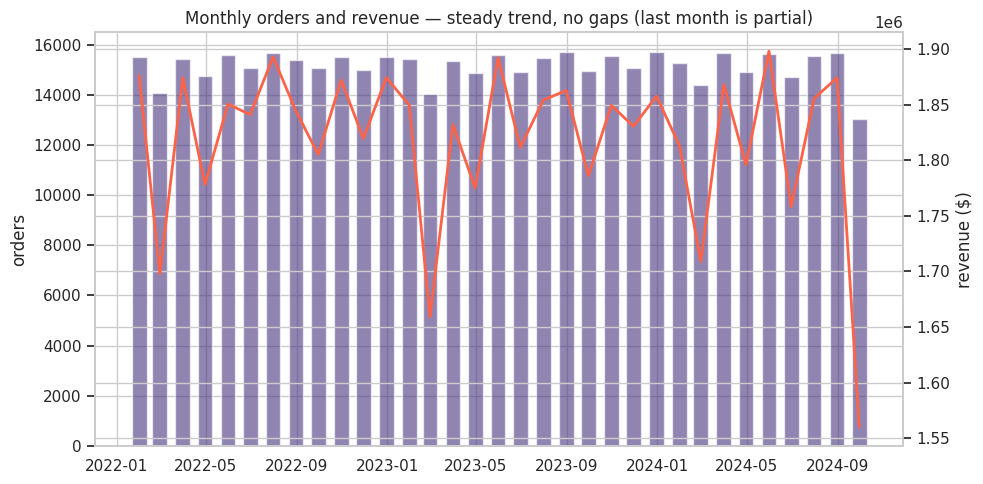

In [17]:
monthly = (trans.set_index("transaction_timestamp").resample("ME")
           .agg(orders=("transaction_id", "size"), revenue=("order_value", "sum")))
fig, ax1 = plt.subplots()
ax1.bar(monthly.index, monthly["orders"], width=20, alpha=0.6, label="orders")
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["revenue"], color="tomato", lw=2, label="revenue ($)")
ax1.set_title("Monthly orders and revenue — steady trend, no gaps (last month is partial)")
ax1.set_ylabel("orders"); ax2.set_ylabel("revenue ($)")
fig.tight_layout(); plt.show()

### 4.2 Customers

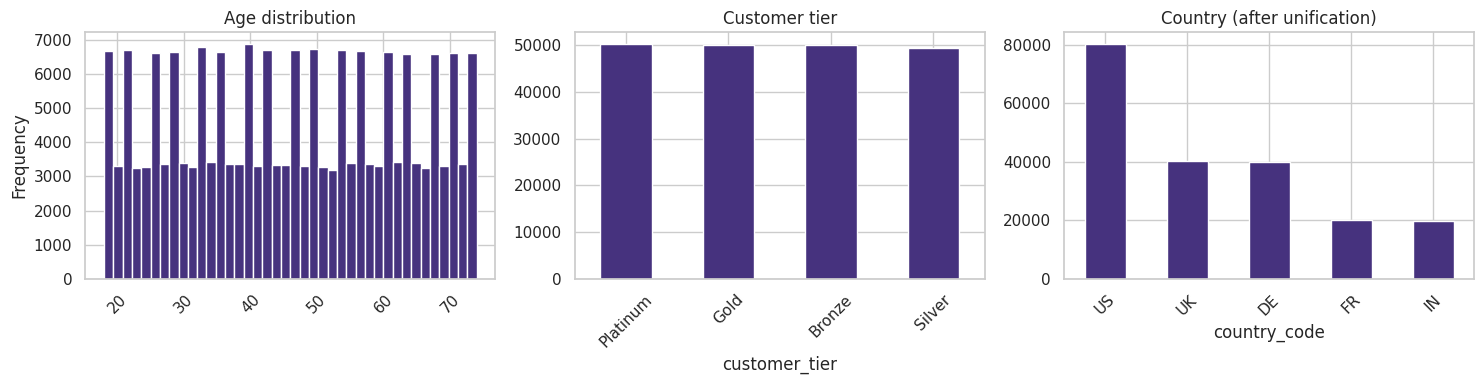

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cust["age"].plot.hist(bins=40, ax=axes[0], title="Age distribution")
cust["customer_tier"].value_counts().plot.bar(ax=axes[1], title="Customer tier")
cust["country_code"].value_counts().plot.bar(ax=axes[2], title="Country (after unification)")
for a in axes: a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

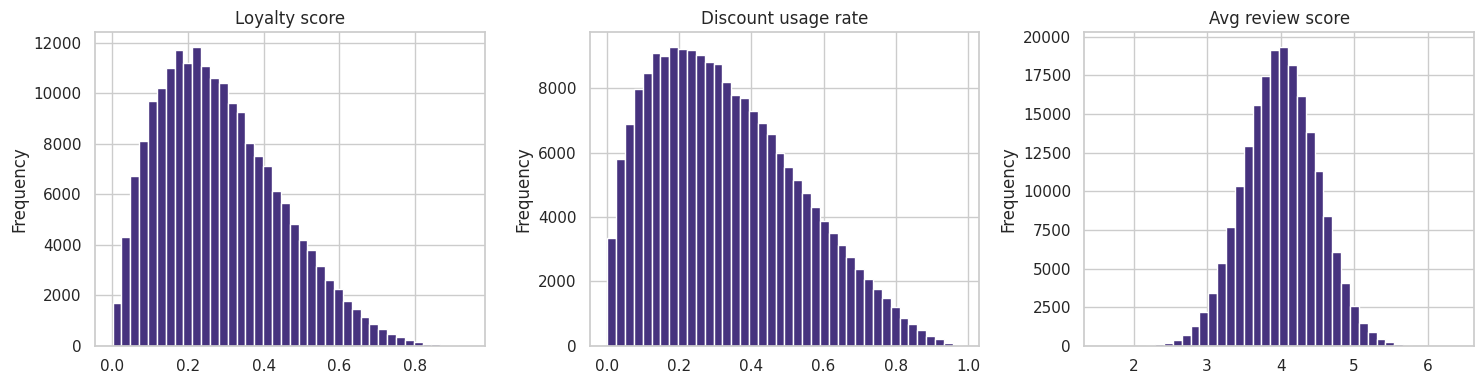

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cust["loyalty_score"].plot.hist(bins=40, ax=axes[0], title="Loyalty score")
cust["discount_usage_rate"].plot.hist(bins=40, ax=axes[1], title="Discount usage rate")
cust["avg_review_score"].plot.hist(bins=40, ax=axes[2], title="Avg review score")
plt.tight_layout(); plt.show()

All four tiers and all five countries are near-perfectly balanced — the population is synthetic and uniform. `loyalty_score` and `discount_usage_rate` are the only profile attributes with real spread.

### 4.3 Transactions

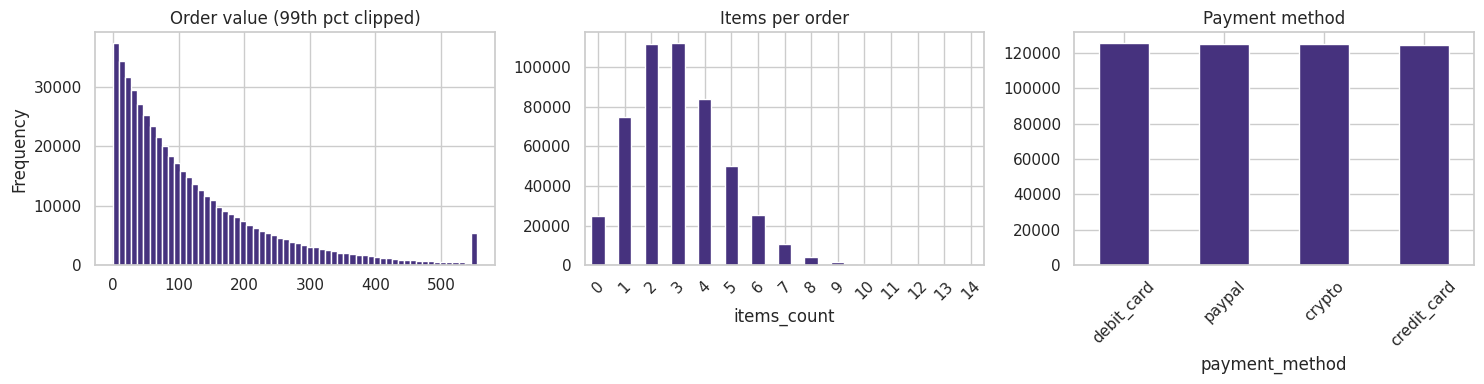

count   500,000.000
mean        120.030
std         120.260
min           0.000
25%          34.420
50%          83.080
75%         166.390
max       1,670.020


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
trans["order_value"].clip(upper=trans["order_value"].quantile(0.99)).plot.hist(
    bins=60, ax=axes[0], title="Order value (99th pct clipped)")
trans["items_count"].value_counts().sort_index().plot.bar(ax=axes[1], title="Items per order")
trans["payment_method"].value_counts().plot.bar(ax=axes[2], title="Payment method")
for a in axes[1:]: a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
print(trans["order_value"].describe().round(2).to_string())

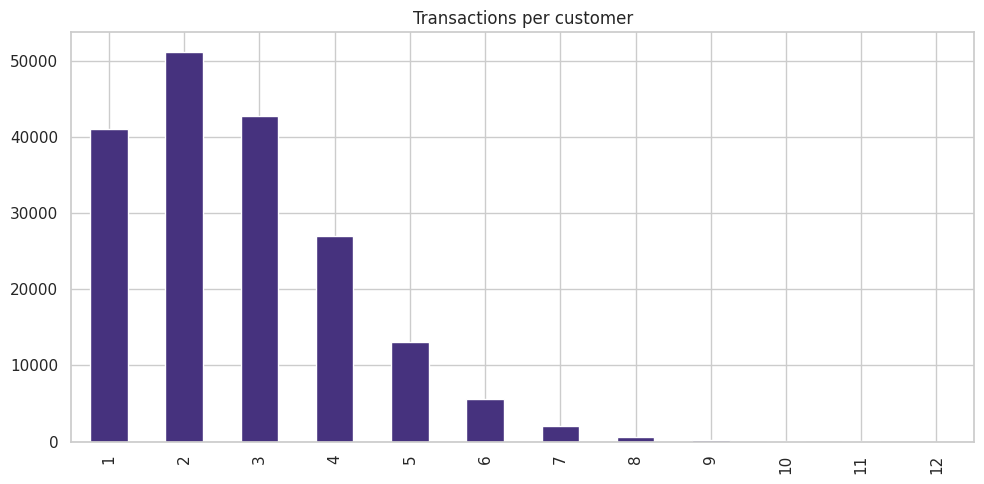

customers with >= 1 transaction: 183,541 of 200,000 (91.8%) | mean 2.72, max 12


In [21]:
tx_per_cust = trans.groupby("customer_id").size()
fig, ax = plt.subplots()
tx_per_cust.value_counts().sort_index().plot.bar(ax=ax, title="Transactions per customer")
plt.tight_layout(); plt.show()
print(f"customers with >= 1 transaction: {tx_per_cust.size:,} of {len(cust):,} "
      f"({tx_per_cust.size/len(cust):.1%}) | mean {tx_per_cust.mean():.2f}, max {tx_per_cust.max()}")

### 4.4 Sessions

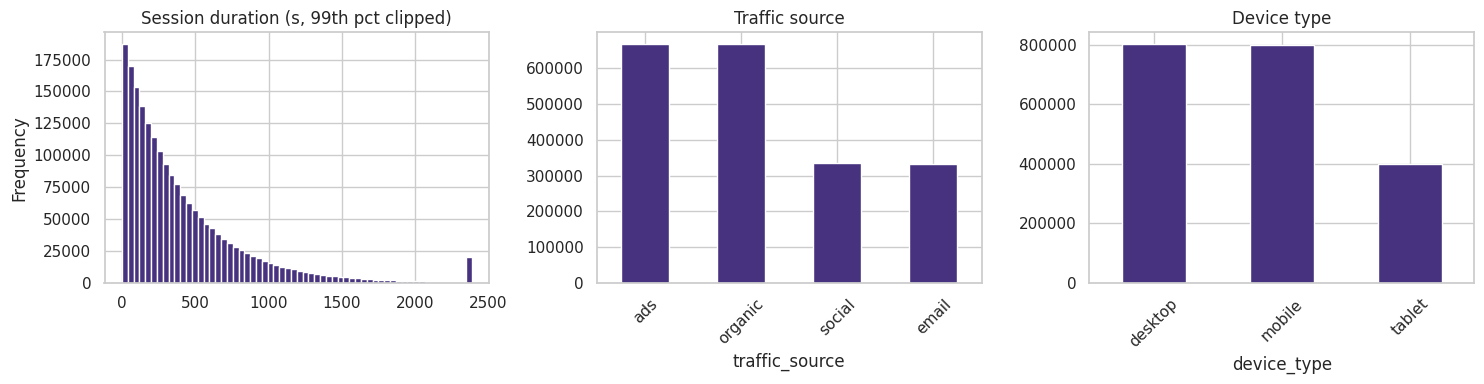

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sess["session_duration"].clip(upper=sess["session_duration"].quantile(0.99)).plot.hist(
    bins=60, ax=axes[0], title="Session duration (s, 99th pct clipped)")
sess["traffic_source"].value_counts().plot.bar(ax=axes[1], title="Traffic source")
sess["device_type"].value_counts().plot.bar(ax=axes[2], title="Device type")
for a in axes[1:]: a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

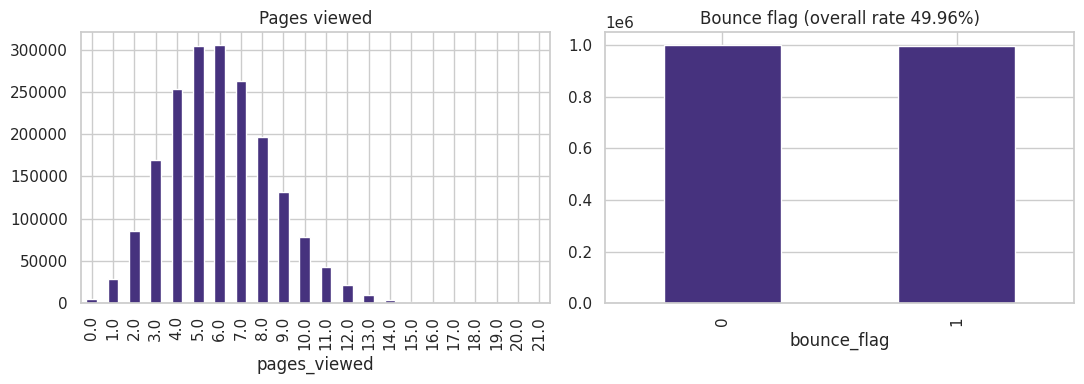

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sess["pages_viewed"].value_counts().sort_index().plot.bar(ax=axes[0], title="Pages viewed")
sess["bounce_flag"].value_counts().plot.bar(ax=axes[1], title=f"Bounce flag (overall rate {sess['bounce_flag'].mean():.2%})")
plt.tight_layout(); plt.show()

### 4.5 Context tables (geo & campaigns)

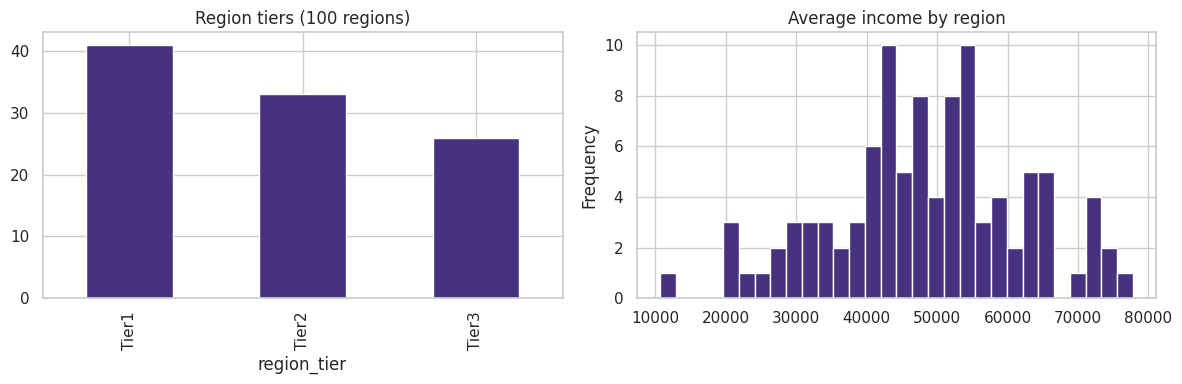

,campaign_id,campaign_type,campaign_budget,region_target,start_date,end_date
0,0,Affiliate,"$46,187",region_33,2022-06-06,2022-09-24
1,1,Email,"$148,311",region_7,2022-02-16,2022-05-30
2,2,Email,"$396,598",region_39,2022-11-20,2023-01-18


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
geo_data["region_tier"].value_counts().sort_index().plot.bar(ax=axes[0], title="Region tiers (100 regions)")
geo_data["average_income"].plot.hist(bins=30, ax=axes[1], title="Average income by region")
plt.tight_layout(); plt.show()
campaigns.head(3)

## 5. Target variable analysis
`train.csv` gives the competition label for 160k customers: **20.3% positive** — a moderately imbalanced binary target.

### 5.1 Does the label match the project document's `repeat_90d` definition?
The project documentation defines the target as *"a second order within 90 days of the first delivered order."* This dataset has no order status or delivery timestamps, so the closest reconstruction from `transactions` is a second transaction within 90 days of the first. Testing that reconstruction against the provided labels:

In [25]:
t_sorted = trans.sort_values(["customer_id", "transaction_timestamp"])
first_tx = t_sorted.groupby("customer_id")["transaction_timestamp"].first()
second_tx = t_sorted.groupby("customer_id")["transaction_timestamp"].nth(1)

check = train.set_index("customer_id")[["target"]].copy()
check["repeat_90d_reconstructed"] = ((second_tx - first_tx) <= pd.Timedelta(days=90)).reindex(check.index).fillna(False).astype(int)

agreement = (check["target"] == check["repeat_90d_reconstructed"]).mean()
print(f"agreement with reconstructed repeat_90d: {agreement:.1%}")

by_count = train.set_index("customer_id").join(tx_per_cust.rename("n_tx"))
print("positive rate by transactions-per-customer (6 = 6+):")
print(by_count.groupby(by_count["n_tx"].clip(upper=6))["target"].mean().round(3).to_string())

agreement with reconstructed repeat_90d: 74.0%
positive rate by transactions-per-customer (6 = 6+):
n_tx
1.000   0.205
2.000   0.205
3.000   0.202
4.000   0.205
5.000   0.195
6.000   0.196


/tmp/ipykernel_1060/3837739624.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  check["repeat_90d_reconstructed"] = ((second_tx - first_tx) <= pd.Timedelta(days=90)).reindex(check.index).fillna(False).astype(int)


**Finding: the provided label is NOT the documented `repeat_90d` label.** Agreement is only ~74%, and the positive rate is flat (~0.20) across every transaction count — a real repeat-purchase flag would rise sharply with order count. The documentation was written against a planned Olist-style schema; the actual competition data uses its own precomputed target. **Modeling (Phase 3+) must train against the `train.csv` labels as given** and note this divergence in the final report.

### 5.2 What does correlate with the target?

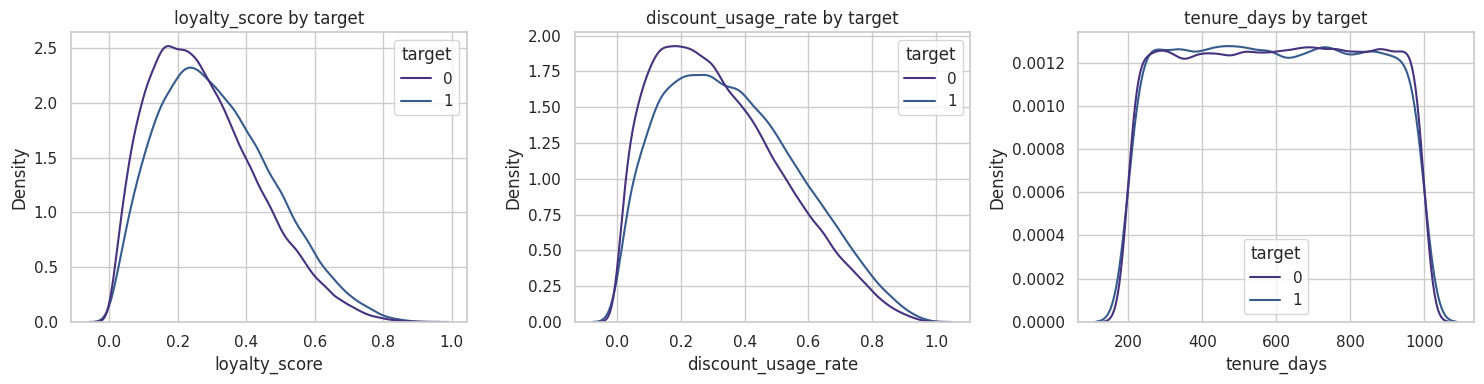

In [26]:
df_t = train.merge(cust, on="customer_id")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["loyalty_score", "discount_usage_rate", "tenure_days"]):
    sns.kdeplot(data=df_t, x=col, hue="target", common_norm=False, ax=ax)
    ax.set_title(f"{col} by target")
plt.tight_layout(); plt.show()

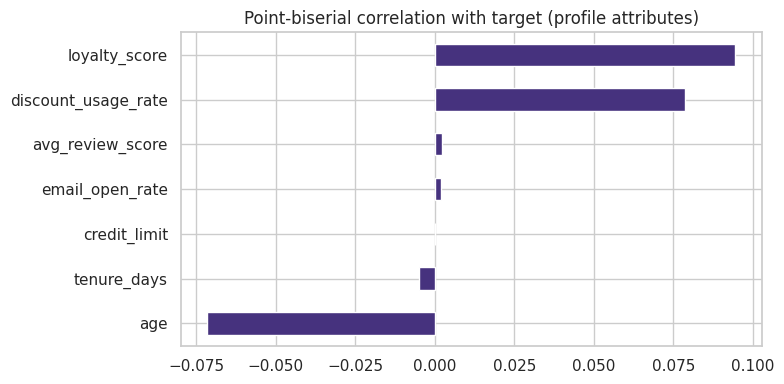

age                   -0.071
tenure_days           -0.005
credit_limit          -0.000
email_open_rate        0.002
avg_review_score       0.002
discount_usage_rate    0.079
loyalty_score          0.095


In [27]:
num_cols = ["age", "loyalty_score", "email_open_rate", "discount_usage_rate",
            "avg_review_score", "credit_limit", "tenure_days"]
corr = df_t[num_cols + ["target"]].corr()["target"].drop("target").sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
corr.plot.barh(ax=ax, title="Point-biserial correlation with target (profile attributes)")
plt.tight_layout(); plt.show()
print(corr.round(4).to_string())

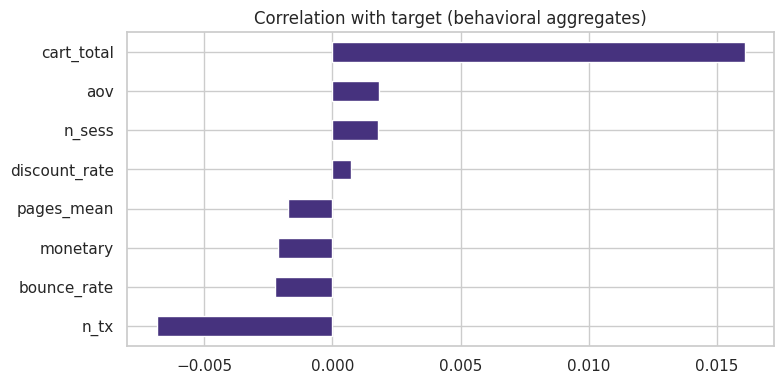

n_tx            -0.007
bounce_rate     -0.002
monetary        -0.002
pages_mean      -0.002
discount_rate    0.001
n_sess           0.002
aov              0.002
cart_total       0.016


In [28]:
# Behavioral aggregates vs target (quick per-customer rollup, cleaned tables)
beh = (trans.groupby("customer_id")
       .agg(n_tx=("transaction_id", "size"), monetary=("order_value", "sum"),
            aov=("order_value", "mean"), discount_rate=("discount_applied", "mean"))
       .join(sess.groupby("customer_id")
             .agg(n_sess=("session_id", "size"), bounce_rate=("bounce_flag", "mean"),
                  pages_mean=("pages_viewed", "mean"), cart_total=("cart_additions", "sum"))))
df_b = train.set_index("customer_id").join(beh)
bcorr = df_b[["n_tx", "monetary", "aov", "discount_rate", "n_sess", "bounce_rate",
              "pages_mean", "cart_total", "target"]].corr()["target"].drop("target").sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
bcorr.plot.barh(ax=ax, title="Correlation with target (behavioral aggregates)")
plt.tight_layout(); plt.show()
print(bcorr.round(4).to_string())

## 6. Key findings & implications for Phase 2

**Data quality**
1. All identifiers join perfectly; no duplicate rows; train/test are disjoint and cover all customers. The database phase can rely on these keys.
2. The raw files are deliberately dirty: mixed boolean encodings, currency-as-text, inconsistent country/device/source spellings, and `"unknown"` ages. All fixed with deterministic rules in section 3; imputation of the remaining small gaps (`email_open_rate` 11%, `age`/`avg_review_score`/`pages_viewed` ~5%) is deferred to the preprocessing pipeline.
3. The 5 `noise_customer_*` and 2 `noise_trans_*` columns are confirmed signal-free and dropped.

**Business signal**
4. The target is moderately imbalanced (20.3% positive) — class weighting or resampling will be needed, and **PR-AUC should be reported alongside ROC-AUC**.
5. The provided label does **not** match the documentation's `repeat_90d` definition (~74% agreement, flat positive rate across transaction counts). Phase 3 must model the given `train.csv` labels and document this divergence.
6. `loyalty_score` (+0.095), `discount_usage_rate` (+0.083) and `age` (-0.078) are the strongest profile attributes (univariate AUC ~0.55-0.57). Behavioral aggregates from transactions/sessions add only small further correlations individually — predictive power is spread thin across many weak features, which favors gradient-boosted trees over linear models.
7. Time coverage is uniform (Jan 2022 - Sep 2024) with no seasonality or drift, so a random stratified split is defensible; a time-based split remains the safer validation choice per the project document.

**Handoff to Phase 2 (feature engineering):** build per-customer RFM-style aggregates from the cleaned `transactions` and `sessions` tables, enriched with `geo_data` and campaign exposure — while respecting the leakage rules in the project document.

In [29]:
# Persist cleaned tables for the next phases (git-ignored folder)
import os
os.makedirs(DATA + "cleaned", exist_ok=True)
cust.to_csv(DATA + "cleaned/customers_clean.csv", index=False)
trans.to_csv(DATA + "cleaned/transactions_clean.csv", index=False)
sess.to_csv(DATA + "cleaned/sessions_clean.csv", index=False)
print("saved:", os.listdir(DATA + "cleaned"))

saved: ['customers_clean.csv', 'sessions_clean.csv', 'transactions_clean.csv']
